In [ ]:
# memory footprint support libraries/code
# %ln -sf /opt/bin/nvidia-smi /usr/bin/nvidia-smi
# %pip install gputil --q
# %pip install psutil --q
# %pip install humanize --q
import psutil
import humanize
import os
import GPUtil as GPU
GPUs = GPU.getGPUs()
# XXX: only one GPU on Colab and isn’t guaranteed
# gpu = GPUs[0]
def printm():
 process = psutil.Process(os.getpid())
 print("Gen RAM Free: " + humanize.naturalsize( psutil.virtual_memory().available ), " | Proc size: " + humanize.naturalsize( process.memory_info().rss))
#  print("GPU RAM Free: {0:.0f}MB | Used: {1:.0f}MB | Util {2:3.0f}% | Total {3:.0f}MB".format(gpu.memoryFree, gpu.memoryUsed, gpu.memoryUtil*100, gpu.memoryTotal))
printm()

In [6]:
import torch
import torch.nn.functional as F

if torch.cuda.is_available():
    device = torch.device("cuda")
    print('There are %d GPU(s) available.' % torch.cuda.device_count())
    print('We will use the GPU:', torch.cuda.get_device_name(0))

else:
    print('No GPU available, using the CPU instead.')
    device = torch.device("cpu")

No GPU available, using the CPU instead.


### Load Indonesia News Dataset

In [3]:
# dict mapping
label2num = {'pendidikan':0, 'kesehatan':1, 'teknologi':2, 'olahraga':3, 'otomotif':4}

In [2]:
import pandas as pd

train = pd.read_csv('dataset/train.csv', usecols=['title', 'category']).rename(columns={'title': 'text', 'category': 'label'})
test = pd.read_csv('dataset/test.csv', usecols=['title', 'category']).rename(columns={'title': 'text', 'category': 'label'})

train.head()

,text,label
0,10 Jurusan Kuliah yang Langsung Cepat Dapat Kerja,pendidikan
1,"Heboh Kasus Gagal Ginjal pada Anak, IDAI Sorot...",kesehatan
2,Mendukung Indonesia Tanpa Embel-embel,olahraga
3,Apakah Rajin Makan Apel Setiap Hari Baik untuk...,kesehatan
4,"Transjakarta Trayek Cibubur-Cililitan Berubah,...",otomotif


In [24]:
import pandas as pd

# train = pd.DataFrame({'text': train[0], 'label': train[1]})
# test = pd.DataFrame({'text': test[0], 'label': test[1]})

print('Number of training sentences: {:,}\n'.format(train.shape[0]))
print('Number of testing sentences: {:,}\n'.format(test.shape[0]))

# Display 5 random rows from the data.
train.sample(5)

Number of training sentences: 26,220

Number of testing sentences: 6,555



,text,label
1228,Cara Buat NGL Link di Instagram dan WhatsApp,teknologi
16349,Ini Sebabnya Luca Marini Langsung Telepon Ross...,otomotif
1741,Brasil Catat Kematian Pertama di Dunia Akibat ...,kesehatan
1822,"Catur Pamungkas Cedera Bahu, Persebaya Sorot K...",olahraga
11874,Ulik Perbedaan Chery Omoda 5 GT FWD dengan AWD,otomotif


In [4]:
# encode label
train.label = train.label.map(label2num)
test.label = test.label.map(label2num)

### DATA CLEANSING

In [5]:
from nltk.tokenize import word_tokenize
import nltk
import collections

def get_frequent_word(df):
  text = " ".join(list(df['text'].str.lower()))
  word_list = word_tokenize(text)
  word_count = dict(collections.Counter(word_list))
  d_word_freq = pd.DataFrame(data = {'word' : list(word_count.keys()), 'freq': list(word_count.values())})

  return d_word_freq

def cleansing(text, stopword = None):
  word_list = word_tokenize(text.lower())
  word_list = [word for word in word_list if len(word) > 2]
  word_list = [word for word in word_list if word.isalnum()]
  if stopword == None:
    text = ' '.join(word_list)
  else:
    word_list = [word for word in word_list if word not in stopword]
    text = ' '.join(word_list)

  return text

In [7]:
nltk.download('punkt')

# get frekuensi kemunculan kata
d_w_f = get_frequent_word(train)

# cek alphanumeric
d_w_f['is_alnum'] = d_w_f.word.str.isalnum()

# select only aphanumeric word (ignore punctuation)
d_w_f_selected = d_w_f[d_w_f['is_alnum'] == True].sort_values(by = 'freq', ascending = False)
print(d_w_f_selected.head(15))
print(d_w_f_selected.tail(15))

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


LookupError: 
**********************************************************************
  Resource [93mpunkt_tab[0m not found.
  Please use the NLTK Downloader to obtain the resource:

  [31m>>> import nltk
  >>> nltk.download('punkt_tab')
  [0m
  For more information see: https://www.nltk.org/data.html

  Attempted to load [93mtokenizers/punkt_tab/english/[0m

  Searched in:
    - 'C:\\Users\\User/nltk_data'
    - 'c:\\Users\\User\\AppData\\Local\\Programs\\Python\\Python312\\nltk_data'
    - 'c:\\Users\\User\\AppData\\Local\\Programs\\Python\\Python312\\share\\nltk_data'
    - 'c:\\Users\\User\\AppData\\Local\\Programs\\Python\\Python312\\lib\\nltk_data'
    - 'C:\\Users\\User\\AppData\\Roaming\\nltk_data'
    - 'C:\\nltk_data'
    - 'D:\\nltk_data'
    - 'E:\\nltk_data'
**********************************************************************


In [11]:
# create stopword list
stopwords = list(d_w_f_selected[d_w_f_selected['freq'] > 5000 | (d_w_f_selected['freq'] < 2)].word)
print(stopwords[:10])

['di', 'dan', '2024', 'yang', 'ini', 'indonesia', 'cara', 'bisa', 'untuk', 'vs']


In [12]:
from tqdm import tqdm

for i in tqdm(range(len(train))):
  train.loc[i, 'text_cleansing'] = cleansing(train.loc[i, 'text'])

for i in tqdm(range(len(test))):
  test.loc[i, 'text_cleansing'] = cleansing(test.loc[i, 'text'])

100%|██████████| 6555/6555 [00:04<00:00, 1338.11it/s]


In [13]:
# training data only use use 25.000 sentences
sentences = train.text_cleansing.values[:25000]
labels = train.label.values[:25000]

# testing data only 5000 sentence
test_sentences = test.text_cleansing.values[:5000]
test_labels = test.label.values[:5000]

### TOKENIZATION & INPUT FORMATTING

#### Load IndoBERT Tokenizer

In [31]:
from transformers import BertTokenizer

print('Loading IndoBERT tokenizer...')
tokenizer = BertTokenizer.from_pretrained('indobenchmark/indobert-base-p1')

Loading IndoBERT tokenizer...


c:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:147: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\User\.cache\huggingface\hub\models--indobenchmark--indobert-base-p1. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


### Tokenize Dataset

In [15]:
import statistics
sent_length = []

# untuk setiap kalimat...
for sent in sentences:
  # tokenize the text and add '[CLS]' and '[SEP]' tokens.
  input_ids = tokenizer.encode(sent, add_special_tokens=True)
  sent_length.append(len(input_ids))

print('Average length = ', sum(sent_length)/len(sent_length))
print('Mediaan length = ', statistics.median(sent_length))

Average length =  12.28836
Mediaan length =  12.0


In [16]:
# Tokenize all of the sentences and map the tokens to their word IDs.
input_ids = []
attention_masks = []

# untuk setiap kalimat...
for sent in sentences:
  encoded_dict = tokenizer.encode_plus(
                      sent,
                      add_special_tokens = True,
                      max_length = 15,
                      pad_to_max_length = True,
                      return_attention_mask = True,
                      return_tensors = 'pt',
                  )

  input_ids.append(encoded_dict['input_ids'])
  attention_masks.append(encoded_dict['attention_mask'])

# convert the lists into tensors.
input_ids = torch.cat(input_ids, dim=0)
attention_masks = torch.cat(attention_masks, dim=0)
labels = torch.tensor(labels)

# print sentence 0, now as a list of IDs.
print('Original: ', sentences[0])
print('Token IDs: ', input_ids[0])

Truncation was not explicitly activated but `max_length` is provided a specific value, please use `truncation=True` to explicitly truncate examples to max length. Defaulting to 'longest_first' truncation strategy. If you encode pairs of sequences (GLUE-style) with the tokenizer you can select this strategy more precisely by providing a specific strategy to `truncation`.
/usr/local/lib/python3.10/dist-packages/transformers/tokenization_utils_base.py:2870: FutureWarning: The `pad_to_max_length` argument is deprecated and will be removed in a future version, use `padding=True` or `padding='longest'` to pad to the longest sequence in the batch, or use `padding='max_length'` to pad to a max length. In this case, you can give a specific length with `max_length` (e.g. `max_length=45`) or leave max_length to None to pad to the maximal input size of the model (e.g. 512 for Bert).
  warnings.warn(


Original:  jurusan kuliah yang langsung cepat dapat kerja
Token IDs:  tensor([   2, 4419, 3211,   34,  728,  972,  173,  494,    3,    0,    0,    0,
           0,    0,    0])


In [17]:
from torch.utils.data import TensorDataset, random_split

# combine the training inputs into a TensorDataset.
dataset = TensorDataset(input_ids, attention_masks, labels)

# create a 80-20 train-validation split.

# calculate the number of samples to include in each set.
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

# divide the dataset by randomly selecting samples.
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

print('{:>5,} training samples'.format(train_size))
print('{:>5} validation samples'.format(val_size))

20,000 training samples
 5000 validation samples


In [18]:
from torch.utils.data import DataLoader, RandomSampler, SequentialSampler

# For fine-tuning IndoBERT on a specific task, the authors recommend a batch
# size of 16 or 32.
batch_size = 32

# create the dataloaders for our training and validation sets.
# we'll take training samples in random order.
train_dataloader = DataLoader(
    train_dataset,
    sampler = RandomSampler(train_dataset),
    batch_size = batch_size
)

validation_dataloader = DataLoader(
    val_dataset,
    sampler = SequentialSampler(val_dataset),
    batch_size = batch_size
)

### Train Classification Model

In [19]:
from transformers import BertForSequenceClassification, AutoModel, AdamW, BertConfig

model = BertForSequenceClassification.from_pretrained(
    'indobenchmark/indobert-base-p1',
    num_labels = 5,
    )

# tell pytorch to run this model on GPU
model.cuda()

pytorch_model.bin:   0%|          | 0.00/498M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(50000, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSdpaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e

In [20]:
# get all of the model's parameters as a list of tuples
params = list(model.named_parameters())

print('The IndoBERT has {:} different named parameters.\n'.format(len(params)))

print('=== Embedding Layer ===\n')

for p in params[0:5]:
  print("{:<55} {:>12}".format(p[0], str(tuple(p[1].size()))))

print('\n=== First Transformer ===')

for p in params[5:21]:
  print('{:<55} {:>12}'.format(p[0], str(tuple(p[1].size()))))

print('\n=== Output Layer ===\n')

for p in params[-4:]:
  print("{:<55} {:>12}".format(p[0], str(tuple(p[1].size()))))

The IndoBERT has 201 different named parameters.

=== Embedding Layer ===

bert.embeddings.word_embeddings.weight                  (50000, 768)
bert.embeddings.position_embeddings.weight                (512, 768)
bert.embeddings.token_type_embeddings.weight                (2, 768)
bert.embeddings.LayerNorm.weight                              (768,)
bert.embeddings.LayerNorm.bias                                (768,)

=== First Transformer ===
bert.encoder.layer.0.attention.self.query.weight          (768, 768)
bert.encoder.layer.0.attention.self.query.bias                (768,)
bert.encoder.layer.0.attention.self.key.weight            (768, 768)
bert.encoder.layer.0.attention.self.key.bias                  (768,)
bert.encoder.layer.0.attention.self.value.weight          (768, 768)
bert.encoder.layer.0.attention.self.value.bias                (768,)
bert.encoder.layer.0.attention.output.dense.weight        (768, 768)
bert.encoder.layer.0.attention.output.dense.bias              (768,)
b

### Optimizer & Learning Rate Scheduler

In [21]:
optimizer = AdamW(model.parameters(),
                  lr = 2e-5,
                  eps = 1e-8
                  )

/usr/local/lib/python3.10/dist-packages/transformers/optimization.py:591: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  warnings.warn(


In [22]:
from transformers import get_linear_schedule_with_warmup

epochs = 3

# total number of training steps is [number of batches] x [number of epochs]
# note that this is not the same as the number of training samples

print('jumlah batch: ', len(train_dataloader))
total_steps = len(train_dataloader) * epochs

# create the learning rate scheduler.
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps = 0,
    num_training_steps = total_steps
)

jumlah batch:  625


### training loop

In [23]:
# define a helper a function for calculation accuracy

import numpy as np

# fungsi untuk menghitung akurasi dari prediksi model vs label
def flat_accuracy(preds, labels):
  pred_flat = np.argmax(preds, axis=1).flatten()
  labels_flat = labels.flatten()
  return np.sum(pred_flat == labels_flat) / len(labels_flat)

In [24]:
# helper function for formatting elapsed times as hh:mm:ss

import time
import datetime

def format_time(elapsed):
  '''
  Takes a time in seconds and returns a string hh:mm:ss
  '''
  # round to the nearest second.
  elapsed_rounded = int(round(elapsed))

  # format as hh:mm:ss
  return str(datetime.timedelta(seconds=elapsed_rounded))

In [25]:
import random
import numpy as np

# list variable for store training and validation loss, validation accuracy, and timings.
training_stats = []

# measure the total training time for the whole run
total_t0 = time.time()

# for each epoch...
for epoch_i in range(0, epochs):
  #===================================
  #             Training
  #===================================
  print("")
  print('======== Epoch {:} / {:} ========'.format(epoch_i + 1, epochs))
  print('Training...')

  # measure how long the training epoch takes
  t0 = time.time()

  # reset the total loss for this epoch
  total_train_loss = 0

  # put the model into training mode
  model.train()

  # for each batch of training data...
  for step, batch in enumerate(train_dataloader):

    # progress update every 20 batches.
    if step % 20 == 0 and not step == 0:
      elapsed = format_time(time.time() - t0)
      # report progress
      print('   Batch {:>5,}  of  {:>5,}.   Elapsed: {:}.'.format(step, len(train_dataloader), elapsed))

    # 'batch' contains three pytorch tensors:
    #   [0]:  input ids
    #   [1]:  attention masks
    #   [2]:  labels
    b_input_ids = batch[0].to(device)
    b_input_mask = batch[1].to(device)
    b_labels = batch[2].to(device)

    # always clear any previously calculated gradients before performing a backward pass
    model.zero_grad()

    # perform a forward pass (evaluate the model on this training batch)
    # token_type_ids is same as the "segment ids", which differentiates
    # sentence 1 and 2 in sentence-pair tasks
    loss, logits = model(
        b_input_ids,
        token_type_ids=None,
        attention_mask=b_input_mask,
        labels=b_labels
        ).to_tuple()

    # accumulate the training loss over all of the batches
    # calculate the aveerage loss at the end
    total_train_loss += loss.item()

    # perform a backward pass to calculate the gradients
    loss.backward()

    # clip the norm of the gradients to 1.0
    # this is to help prevent the "exploding gradients" problem
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

    # update parameters and take a step using the computed gradient
    optimizer.step()

    # update the learning rate
    scheduler.step()

  # calculate the average loss over all of the batches
  avg_train_loss = total_train_loss / len(train_dataloader)

  # measure how long this epoch took
  training_time = format_time(time.time() - t0)

  print("")
  print(" Average training loss: {0:.2f}".format(avg_train_loss))
  print(" Training epoch took:  {:}".format(training_time))

  #===================================
  #             Validation
  #===================================
  print("")
  print("Running Validation...")

  t0 = time.time()

  # put the model in evaluation mode (batchnorm, dropout disable)
  model.eval()

  # tracking variables
  total_eval_accuracy = 0
  total_eval_loss = 0
  nb_eval_steps = 0

  # evaluate data for one epoch
  for batch in validation_dataloader:
    # 'batch' contains three pytorch tensors:
    # [0]:  input ids
    # [1]:  attention masks
    # [2]:  labels
    b_input_ids = batch[0].to(device)
    b_input_mask = batch[1].to(device)
    b_labels = batch[2].to(device)

    # deactivate autogard, it will reduce memory usage and speed up computations
    # but you won't be able to backprop (which you don't want in an eval script)
    with torch.no_grad():

      # forward pass, calculate logit predictions
      (loss, logits) = model (
          b_input_ids,
          token_type_ids=None,
          attention_mask=b_input_mask,
          labels=b_labels
          ).to_tuple()

    # accumulate the validation loss
    total_eval_loss += loss.item()

    # move logts and labels on CPU
    logits = logits.detach().cpu().numpy()
    label_ids = b_labels.to('cpu').numpy()

    # calculate the accuracy for this batch of test sentences, and
    # accumulate it over all batches.
    total_eval_accuracy += flat_accuracy(logits, label_ids)

  # Report the final accuracy for this validation run
  avg_val_accuracy = total_eval_accuracy / len(validation_dataloader)
  print("   Accuracy: {0:.2f}".format(avg_val_accuracy))

  # calculate the average loss over all of the batches.
  avg_val_loss = total_eval_loss / len(validation_dataloader)

  # measure how long the validation run took
  validation_time = format_time(time.time() - t0)

  print("   validation loss: {0:.2f}".format(avg_val_loss))
  print("   validation took: {:}".format(validation_time))

  # record all statistics from this epoch
  training_stats.append(
      {
            'Epoch': epoch_i + 1,
            'Training Loss': avg_train_loss,
            'validation Loss': avg_val_loss,
            'Validation Accuracy': avg_val_accuracy,
            'Training Time': training_time,
            'Validation Time': validation_time
      }
  )

print("")
print("Training complete!")

print("Total training took {:} (h:mm:ss)".format(format_time(time.time() - total_t0)))



======== Epoch 1 / 3 ========
Training...
   Batch    20  of    625.   Elapsed: 0:00:04.
   Batch    40  of    625.   Elapsed: 0:00:06.
   Batch    60  of    625.   Elapsed: 0:00:09.
   Batch    80  of    625.   Elapsed: 0:00:11.
   Batch   100  of    625.   Elapsed: 0:00:13.
   Batch   120  of    625.   Elapsed: 0:00:16.
   Batch   140  of    625.   Elapsed: 0:00:18.
   Batch   160  of    625.   Elapsed: 0:00:20.
   Batch   180  of    625.   Elapsed: 0:00:22.
   Batch   200  of    625.   Elapsed: 0:00:25.
   Batch   220  of    625.   Elapsed: 0:00:27.
   Batch   240  of    625.   Elapsed: 0:00:29.
   Batch   260  of    625.   Elapsed: 0:00:31.
   Batch   280  of    625.   Elapsed: 0:00:34.
   Batch   300  of    625.   Elapsed: 0:00:36.
   Batch   320  of    625.   Elapsed: 0:00:38.
   Batch   340  of    625.   Elapsed: 0:00:41.
   Batch   360  of    625.   Elapsed: 0:00:43.
   Batch   380  of    625.   Elapsed: 0:00:45.
   Batch   400  of    625.   Elapsed: 0:00:48.
   Batch   420  o

In [26]:
# view the summary of the training process

import pandas as pd

# display floats with two decimal places
# pd.set_option('precision', 2)
pd.options.display.max_rows = 15

# create a dataframe from our training statistics
df_stats = pd.DataFrame(data=training_stats)

# use the 'epoch' as the row index.
df_stats = df_stats.set_index('Epoch')

# display the table
df_stats

,Training Loss,validation Loss,Validation Accuracy,Training Time,Validation Time
Epoch,,,,,
1,0.242824,0.188170,0.939689,0:01:14,0:00:05
2,0.101279,0.176416,0.947054,0:01:16,0:00:05
3,0.050272,0.194751,0.946059,0:01:16,0:00:05


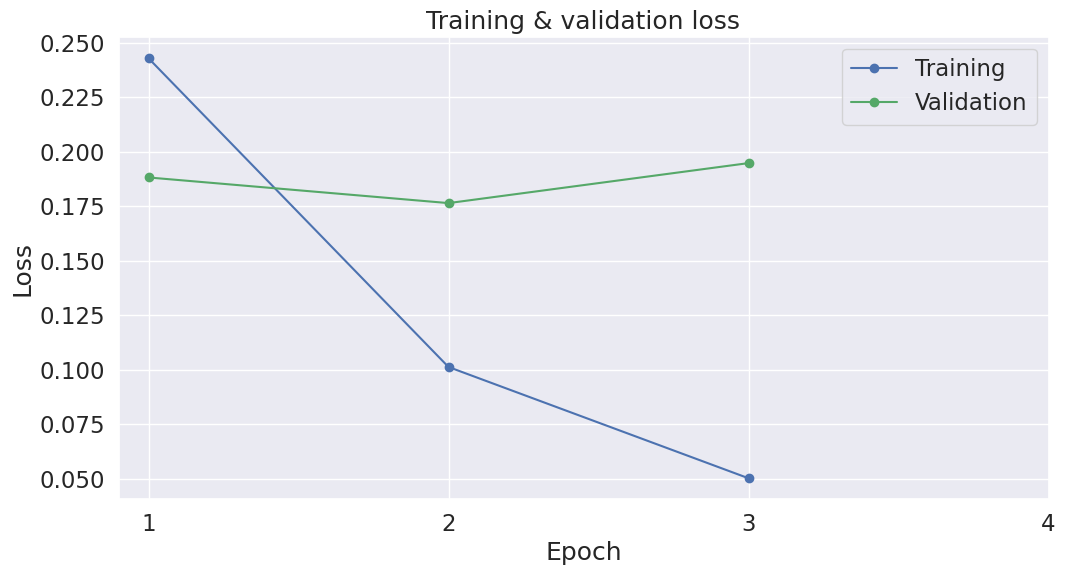

In [27]:
import matplotlib.pyplot as plt
# % matplotlib inline

import seaborn as sns

# use plot styling from seaborn.
sns.set(style='darkgrid')

# increase the plot size and font size
sns.set(font_scale=1.5)
plt.rcParams["figure.figsize"] = (12,6)

# plot the learning curve
plt.plot(df_stats['Training Loss'], 'b-o', label="Training")
plt.plot(df_stats['validation Loss'], 'g-o', label="Validation")

# label the plot
plt.title("Training & validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.xticks([1, 2, 3, 4])

plt.show()

### Performance on test set

In [29]:
# data preparation

# tokenize all of the sentences and map the tokens to their word IDs
input_ids = []
attention_masks = []

# for every sentence...
for sent in test_sentences:
  # 'encode_plus' will:
  # (1) Tokenize the sentence
  # (2) Prepend the '[CLS]' token to the start
  # (3) Prepend the '[SEP]' token to the end
  # (4) Map tokens to their IDs
  # (5) Pad or truncate the sentence to 'max_length'
  # (6) Create attention masks for [PAD] tokens
  encoded_dict = tokenizer.encode_plus(
      sent,
      add_special_tokens = True, # add '[CLS]' nad '[SEP]'
      max_length = 15,
      pad_to_max_length = True,
      return_attention_mask = True,
      return_tensors = 'pt',
  )

  # add the encoded sentence to the list
  input_ids.append(encoded_dict['input_ids'])

  # and its attention mask (simply differentiates padding from non-padding)
  attention_masks.append(encoded_dict['attention_mask'])

# convert the lists into tensors
input_ids = torch.cat(input_ids, dim=0)
attention_masks = torch.cat(attention_masks, dim=0)
labels = torch.tensor(test_labels)

# set the batch size
batch_size = 32

# create the dataloader
prediction_data = TensorDataset(input_ids, attention_masks, labels)
prediction_sampler = SequentialSampler(prediction_data)
prediction_dataloader = DataLoader(prediction_data, sampler=prediction_sampler, batch_size=batch_size)

/usr/local/lib/python3.10/dist-packages/transformers/tokenization_utils_base.py:2870: FutureWarning: The `pad_to_max_length` argument is deprecated and will be removed in a future version, use `padding=True` or `padding='longest'` to pad to the longest sequence in the batch, or use `padding='max_length'` to pad to a max length. In this case, you can give a specific length with `max_length` (e.g. `max_length=45`) or leave max_length to None to pad to the maximal input size of the model (e.g. 512 for Bert).
  warnings.warn(


In [30]:
# evaluate on test set

# prediciton on test set

print('Predicting labels for {:,} test sentences...'.format(len(input_ids)))

# put model in evaluation mode
model.eval()

# tracking variables
predictions, true_labels = [], []

# predict
for batch in prediction_dataloader:
  # add batch to GPU
  batch = tuple(t.to(device) for t in batch)

  # unpack thei nputs from our dataloader
  b_input_ids, b_input_mask, b_labels = batch

  # telling the model not to compute or store gradients, saving memory and speeding up prediction
  with torch.no_grad():
    # forward pass, calculate logit predictions
    outputs = model(b_input_ids, token_type_ids=None,
                    attention_mask=b_input_mask)

    logits = outputs[0]

    # move logits and labels to cpu
    logits = logits.detach().cpu().numpy()
    label_ids = b_labels.to('cpu').numpy()

    # store predictions and true labels
    predictions.append(logits)
    true_labels.append(label_ids)

print('   Done.')

Predicting labels for 5,000 test sentences...
   Done.


In [31]:
# calculate accuracy for test dataset
total_accuracy = 0
for batch_num in range(len(predictions)):
  total_accuracy += flat_accuracy(predictions[batch_num], true_labels[batch_num])

total_accuracy = total_accuracy/len(predictions)*100
print('Accuracy on test dataset:', total_accuracy)

Accuracy on test dataset: 95.68073248407643


### Saving model

In [37]:
import os

# saving best-practices: if you use defaults names for the model, you can reaload it using from_ptretrained()
# output_dir = '/content/drive/MyDrive/code skripsi/model'
local_output_dir = 'C:\Users\User\Documents\berkas epan\berkas kuliah\SKRIPSI\code\fine-tuning IndoBERT\model'

print("Saving model to %s" % local_output_dir)

# save a trained model, configuration and tokenizer using 'save_pretrained()'
# they can then be realoded using 'from_pretrained()'
model_to_save = model.module if hasattr(model, 'module') else model # take care of distributed/parallel training
model_to_save.save_pretrained(local_output_dir)
tokenizer.save_pretrained(local_output_dir)

Saving model to /content/drive/MyDrive/code skripsi/model


('/content/drive/MyDrive/code skripsi/model/tokenizer_config.json',
 '/content/drive/MyDrive/code skripsi/model/special_tokens_map.json',
 '/content/drive/MyDrive/code skripsi/model/vocab.txt',
 '/content/drive/MyDrive/code skripsi/model/added_tokens.json')

In [4]:
local_output_dir = 'model'

### Load model back from disk


In [7]:
from transformers import BertForSequenceClassification, BertTokenizer

# load a trained model and vocabulary that you have fine-tuned
model = BertForSequenceClassification.from_pretrained(local_output_dir)
tokenizer = BertTokenizer.from_pretrained(local_output_dir)

# copy the model to the gpu
model.to(device)

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(50000, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSdpaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e

In [9]:
category = {'pendidikan': 0, 'kesehatan': 1, 'teknologi': 2, 'olahraga':3, 'otomotif': 4}
i2w = {index: word for word, index in category.items()}

### Test fine-tuned model on sample sentences

In [10]:
def predict_news(text):
    subwords = tokenizer.encode(text)
    subwords = torch.LongTensor(subwords).view(1, -1).to(model.device)

    logits = model(subwords)[0]
    label = torch.topk(logits, k=1, dim=-1)[1].squeeze().item()

    print(f'Text: {text} | Label: {i2w[label]} ({F.softmax(logits, dim=-1).squeeze()[label] * 100:.3f}%)')

In [11]:
# pendidikan
text = "50 Pelamar CPNS Pemprov Jakarta Berubah Status 'Lulus' Jadi 'Tidak Lulus', Apa Sebabnya?"

predict_news(text)

Text: 50 Pelamar CPNS Pemprov Jakarta Berubah Status 'Lulus' Jadi 'Tidak Lulus', Apa Sebabnya? | Label: pendidikan (99.910%)


In [39]:
# kesehatan
text = '7 dari 10 Anak di Korea Selatan Idap Rabun Jauh, gegara Pandemi?'

predict_news(text)

Text: 7 dari 10 Anak di Korea Selatan Idap Rabun Jauh, gegara Pandemi? | Label: kesehatan (99.632%)


In [41]:
# tekonologi
text = 'Xiaomi Smart Band 9 Rilis Global, Fitur Belimpah Harga Rp 600 Ribuan'

predict_news(text)

Text: Xiaomi Smart Band 9 Rilis Global, Fitur Belimpah Harga Rp 600 Ribuan | Label: teknologi (99.938%)


In [42]:
# olahraga
text = 'Sport Festival Jadi Gebrakan Adil Hakim Menuju Kursi Ketua Umum Kormi Nasional'

predict_news(text)

Text: Sport Festival Jadi Gebrakan Adil Hakim Menuju Kursi Ketua Umum Kormi Nasional | Label: olahraga (99.845%)


In [43]:
# otomotif
text = 'Modifikasi Toyota Hilux Jadi Kendaraan Militer Siap Tempur?'

predict_news(text)

Text: Modifikasi Toyota Hilux Jadi Kendaraan Militer Siap Tempur? | Label: otomotif (99.932%)
